# MCDI503 · Evaluación Sumativa 1 — Fase 1
## EDA reproducible: supervivencia en el Titanic

- **Integrantes:** Jorge Gutiérrez J. - Felipe Palma B. - Cristian Grandón G. 
- **Docente:** Sergio Paraíso M. 
- **Fecha:** Noviembre 2026
- **Dataset:** `titanic`, colección de ejemplos de Seaborn. Se utilizará este dataset por su mayor riqueza analítica. 


**Propósito:** caracterizar la calidad de los datos y describir patrones iniciales de supervivencia, sin establecer causalidad.

> **Alcance:** primera implementación exploratoria. No se realizan pruebas de hipótesis, modelos predictivos ni afirmaciones causales.

## 1. Importación de librerías y carga del dataset

En esta primera etapa se configura el entorno de trabajo mediante la importación de las librerías necesarias para la manipulación, exploración y visualización de datos. Posteriormente, se carga el conjunto de datos `titanic`, disponible en la biblioteca Seaborn, que contiene información sobre las características de los pasajeros y su supervivencia durante el naufragio del Titanic.

Se realizará una inspección inicial de los registros, dimensiones y tipos de datos, con el propósito de comprender la estructura general del conjunto y verificar su correcta disponibilidad para las etapas posteriores.

Asimismo, se registrarán las versiones de las principales librerías utilizadas, como medida básica de reproducibilidad que permita identificar las condiciones técnicas bajo las cuales se desarrolla el análisis.

Como medida adicional de reproducibilidad, se verificará la disponibilidad de las variables esenciales para el análisis y la validez de la codificación del indicador de supervivencia. Estas comprobaciones permitirán detectar posibles diferencias en la estructura del dataset antes de ejecutar las etapas exploratorias posteriores.

In [1]:
import sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | seaborn {sns.__version__} | numpy {np.__version__} | SO {platform.system()}")

titanic = sns.load_dataset("titanic")
fuente = "Seaborn oficial: sns.load_dataset('titanic')"

# Validación de estructura y variables esenciales
columnas_requeridas = {
    "survived", "pclass", "sex", "age",
    "sibsp", "parch", "fare", "embarked"
}

faltantes = columnas_requeridas - set(titanic.columns)

assert not faltantes, (
    f"Faltan columnas requeridas: {faltantes}"
)

assert titanic["survived"].dropna().isin([0, 1]).all(), (
    "La variable survived contiene valores inesperados"
)

print("Validación inicial de estructura: correcta")
print("Fuente utilizada:", fuente)
titanic.head(8)

Python 3.12.6 | pandas 3.1.1 | seaborn 0.13.2 | numpy 2.5.5 | SO Windows
Validación inicial de estructura: correcta
Fuente utilizada: Seaborn oficial: sns.load_dataset('titanic')


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False


In [2]:
print("Dimensiones:", titanic.shape)
titanic.info()

Dimensiones: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


### Análisis de resultados

La carga del dataset se realizó correctamente desde la biblioteca Seaborn, obteniéndose un conjunto de **891 registros y 15 variables**, que representan características demográficas, socioeconómicas y familiares de los pasajeros, además de información relacionada con su supervivencia.

Se identifican variables numéricas, como `age`, `fare`, `sibsp` y `parch`; categóricas, como `sex`, `class` y `embarked`; y binarias, como `survived`, `adult_male` y `alone`. Esta diversidad permite desarrollar análisis descriptivos tanto individuales como comparativos.

La revisión de los tipos de datos confirma que las variables presentan formatos compatibles con su naturaleza. Sin embargo, se observan diferencias en la disponibilidad de información, especialmente en `age` y `deck`, lo que hace necesario realizar un diagnóstico de calidad antes de interpretar sus resultados.

En consecuencia, el conjunto de datos presenta una estructura adecuada para desarrollar el análisis exploratorio propuesto, aunque su utilización requiere considerar la presencia de información incompleta.

## 2. Inspección inicial del dataset

Esta sección tiene como objetivo evaluar preliminarmente la calidad y consistencia de los datos, identificando posibles problemas que puedan afectar su interpretación.

Para ello, se examinará la cantidad y proporción de valores faltantes por variable, la presencia de registros completamente duplicados, los valores únicos y la existencia de edades o tarifas negativas, consideradas incompatibles con el contexto del conjunto de datos.

Este diagnóstico permitirá determinar qué variables presentan mayores restricciones de cobertura y establecer criterios para su utilización en las siguientes etapas, evitando realizar modificaciones que no estén suficientemente justificadas.

In [3]:
print("Tipos y cobertura:")
display(pd.DataFrame({'tipo':titanic.dtypes.astype(str),'nulos':titanic.isna().sum(),'porcentaje_nulos':(titanic.isna().mean()*100).round(2),'valores_unicos':titanic.nunique(dropna=True)}).sort_values('porcentaje_nulos',ascending=False))
print("Duplicados exactos:",int(titanic.duplicated().sum()))
print("Valores inválidos: edad negativa =",int(titanic['age'].lt(0).sum()),"; tarifa negativa =",int(titanic['fare'].lt(0).sum()))
print("Categorías de supervivencia:",titanic['survived'].value_counts(dropna=False).to_dict())
print("Categorías de clase:",titanic['pclass'].value_counts(dropna=False).sort_index().to_dict())

Tipos y cobertura:


,tipo,nulos,porcentaje_nulos,valores_unicos
deck,category,688,77.22,7
age,float64,177,19.87,88
embarked,str,2,0.22,3
embark_town,str,2,0.22,3
sex,str,0,0.00,2
pclass,int64,0,0.00,3
survived,int64,0,0.00,2
fare,float64,0,0.00,248
parch,int64,0,0.00,7
sibsp,int64,0,0.00,7


Duplicados exactos: 107
Valores inválidos: edad negativa = 0 ; tarifa negativa = 0
Categorías de supervivencia: {0: 549, 1: 342}
Categorías de clase: {1: 216, 2: 184, 3: 491}


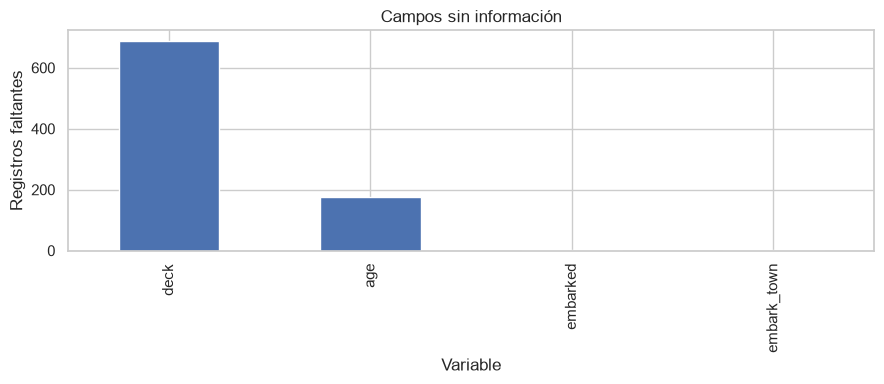

age: 177 nulos (19.9%)
deck: 688 nulos (77.2%)
embarked: 2 nulos (0.2%)
embark_town: 2 nulos (0.2%)


In [4]:
n=len(titanic)
faltantes=titanic.isna().sum().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(9,4))
faltantes[faltantes>0].plot.bar(ax=ax)
ax.set(title="Campos sin información",ylabel="Registros faltantes",xlabel="Variable")
plt.tight_layout();plt.show()
for c in ['age','deck','embarked','embark_town']:
    if c in titanic:
        print(f"{c}: {titanic[c].isna().sum()} nulos ({titanic[c].isna().mean():.1%})")

### Análisis de resultados

El diagnóstico de calidad evidencia que la disponibilidad de información no es homogénea entre las variables del dataset.

La mayor proporción de valores faltantes corresponde a `deck`, con **688 registros sin información (77,22 %)**, seguida de `age`, con **177 registros faltantes (19,87 %)**. Por su parte, `embarked` y `embark_town` presentan únicamente dos valores ausentes cada una (0,22 %).

Estas diferencias tienen implicancias relevantes para el análisis. La elevada ausencia de información en `deck` limita considerablemente su utilidad para realizar comparaciones por cubierta. En cambio, `age` conserva 714 observaciones válidas, suficientes para desarrollar una primera descripción de su distribución, aunque los resultados deben interpretarse exclusivamente respecto de los pasajeros con edad registrada.

Se identificaron **107 registros completamente duplicados**, equivalentes al 12,01 % del total de observaciones. Este resultado indica que existen filas con valores idénticos en todas las variables disponibles, pero no demuestra que correspondan a registros repetidos de una misma persona.

Debido a que el dataset no dispone de un identificador único de pasajeros, diferentes individuos podrían compartir exactamente las mismas características registradas. En consecuencia, eliminar estos registros podría producir una pérdida injustificada de información y alterar las distribuciones observadas.

Por esta razón, se decidió conservar la totalidad de los registros y documentar esta condición como una limitación de calidad, dejando pendiente su evaluación ante la eventual disponibilidad de información identificadora adicional.

Respecto de la consistencia de los valores, no se identificaron edades ni tarifas negativas. Asimismo, las variables `survived` y `pclass` presentan las categorías esperadas para sus respectivas codificaciones.

En síntesis, el conjunto de datos permite continuar con la exploración, pero requiere mantener explícitas las restricciones asociadas a la información faltante, especialmente en las variables `age` y `deck`.

## 3. Estadísticas descriptivas

En esta sección se realizará una caracterización estadística inicial de las principales variables del dataset, utilizando medidas de tendencia central, dispersión y posición para las variables numéricas, junto con frecuencias absolutas y relativas para las categóricas.

Se examinarán las distribuciones de edad (`age`), tarifa (`fare`), cantidad de hermanos o cónyuges a bordo (`sibsp`) y cantidad de padres o hijos a bordo (`parch`). Asimismo, se describirá la composición de los pasajeros según supervivencia, sexo, clase y puerto de embarque.

El propósito es identificar las principales características de la población registrada, reconocer posibles desequilibrios entre categorías y establecer una referencia cuantitativa para las comparaciones posteriores.

In [5]:
# Estadísticas descriptivas de variables numéricas
print(50*"-")
print("Estadísticas descriptivas de variables numéricas")
print(50*"-")

display(titanic[['age','fare','sibsp','parch']].describe().round(2))

# Estadísticas descriptivas de variables categóricas
print(50*"-")
print("Estadísticas descriptivas de variables categóricas")
print(50*"-")

for c in ['survived','sex','pclass','embarked']:
    tabla=pd.DataFrame({'n':titanic[c].value_counts(dropna=False),'porcentaje':(titanic[c].value_counts(dropna=False,normalize=True)*100).round(2)})
    print(f"Frecuencias de {c}");display(tabla)

# Estadísticas de supervivencia
print(f"Supervivencia global: {titanic['survived'].mean():.1%} (n={titanic['survived'].notna().sum()})")

--------------------------------------------------
Estadísticas descriptivas de variables numéricas
--------------------------------------------------


,age,fare,sibsp,parch
count,714.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
25%,20.12,7.91,0.00,0.00
50%,28.00,14.45,0.00,0.00
75%,38.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


--------------------------------------------------
Estadísticas descriptivas de variables categóricas
--------------------------------------------------
Frecuencias de survived


,n,porcentaje
survived,,
0,549,61.62
1,342,38.38


Frecuencias de sex


,n,porcentaje
sex,,
male,577,64.76
female,314,35.24


Frecuencias de pclass


,n,porcentaje
pclass,,
3,491,55.11
1,216,24.24
2,184,20.65


Frecuencias de embarked


,n,porcentaje
embarked,,
S,644,72.28
C,168,18.86
Q,77,8.64
NaN,2,0.22


Supervivencia global: 38.4% (n=891)


### Análisis de resultados

**Variables numéricas**

La edad promedio de los pasajeros con información disponible es de **29,70 años**, mientras que la mediana alcanza los 28 años. El 50 % central de las edades se encuentra aproximadamente entre los 20,12 y 38 años, con valores extremos que van desde 0,42 hasta 80 años. La proximidad entre media y mediana sugiere que la distribución de edades no presenta una asimetría tan pronunciada como la observada en otras variables.

En contraste, la tarifa (`fare`) presenta una media de 32,20 y una mediana de 14,45. Esta diferencia, junto con una desviación estándar de 49,69 y un máximo de 512,33, evidencia una distribución marcadamente asimétrica hacia valores elevados. En consecuencia, la mediana constituye una medida más representativa de la tarifa habitual, al ser menos sensible a los valores extremos.

Respecto de las variables familiares, tanto `sibsp` como `parch` presentan medianas iguales a cero, lo que indica que al menos la mitad de los pasajeros no registra acompañantes en cada una de estas categorías por separado.

**Variables categóricas**

De los 891 pasajeros registrados, **342 sobrevivieron (38,38 %)** y 549 no sobrevivieron (61,62 %). Por lo tanto, la supervivencia representa una proporción minoritaria dentro del conjunto analizado.

La distribución por sexo muestra una mayor presencia de hombres, con 577 registros (64,76 %), frente a 314 mujeres (35,24 %).

En cuanto a la clase del pasaje, predomina la tercera clase, con 491 pasajeros (55,11 %), seguida de primera clase con 216 (24,24 %) y segunda clase con 184 (20,65 %).

Finalmente, Southampton concentra la mayor cantidad de embarques, con 644 registros (72,28 %), seguido de Cherbourg con 168 (18,86 %) y Queenstown con 77 (8,64 %).

En conjunto, los resultados permiten identificar una composición desigual de los pasajeros según sexo, clase y puerto de embarque. Estas diferencias deben considerarse al comparar tasas de supervivencia, ya que los grupos no presentan tamaños equivalentes.

## 4. Construcción de variables derivadas

Con el propósito de ampliar las posibilidades de análisis sin modificar la información original, se construirán dos variables a partir de los campos `sibsp` y `parch`.

La primera, `familia_a_bordo`, representa el tamaño del grupo familiar registrado, considerando al propio pasajero, sus hermanos o cónyuge y sus padres o hijos a bordo. La segunda, `viaja_solo`, identifica aquellos casos en que no se registran acompañantes familiares mediante estas variables.

Estas transformaciones permitirán caracterizar la composición familiar de los pasajeros y explorar posteriormente su relación descriptiva con la supervivencia.

Para garantizar la trazabilidad, las variables se incorporarán en una copia del dataset original. Además, se verificará que la cantidad de registros permanezca inalterada y que la variable derivada `viaja_solo` sea consistente con el indicador `alone` disponible en los datos de origen.

In [6]:
df=titanic.copy(deep=True)
df['familia_a_bordo']=df['sibsp']+df['parch']+1
df['viaja_solo']=df['familia_a_bordo'].eq(1)
assert len(df)==len(titanic)
assert titanic.columns.isin(df.columns).all()
print('Filas antes/después:',len(titanic),len(df))
display(df[['sibsp','parch','familia_a_bordo','viaja_solo']].head(10))
display(df['familia_a_bordo'].value_counts().sort_index().rename_axis('Tamaño familiar').to_frame('Pasajeros'))
if 'alone' in df.columns:
    coinciden=df['viaja_solo'].eq(df['alone'].astype(bool)).sum()
    print('Consistencia con alone:',coinciden,'/',len(df))

Filas antes/después: 891 891


,sibsp,parch,familia_a_bordo,viaja_solo
0,1,0,2,False
1,1,0,2,False
2,0,0,1,True
3,1,0,2,False
4,0,0,1,True
5,0,0,1,True
6,0,0,1,True
7,3,1,5,False
8,0,2,3,False
9,1,0,2,False


,Pasajeros
Tamaño familiar,
1,537
2,161
3,102
4,29
5,15
6,22
7,12
8,6
11,7


Consistencia con alone: 891 / 891


### Análisis de resultados

La construcción de las variables derivadas se realizó conservando los **891 registros originales**, sin eliminar observaciones ni modificar las columnas existentes.

La distribución de `familia_a_bordo` muestra que **537 pasajeros (60,27 %)** no registran acompañantes familiares, mientras que 354 (39,73 %) presentan al menos uno.

Entre quienes registran acompañantes, predominan los grupos familiares de dos personas, con 161 pasajeros, seguidos de los grupos de tres integrantes, con 102. También se observan grupos de mayor tamaño, aunque con frecuencias considerablemente menores, incluyendo siete pasajeros asociados a grupos familiares de once integrantes.

La comparación entre `viaja_solo` y la variable original `alone` presenta una coincidencia de **891 de 891 registros (100 %)**. Esto constituye una verificación de consistencia interna de la transformación, aunque no representa una validación independiente de la información de origen.

Los resultados permiten incorporar una dimensión adicional al análisis exploratorio, relacionada con la presencia de familiares a bordo. No obstante, debe considerarse que estas variables no identifican necesariamente a todos los acompañantes del pasajero, ya que no incluyen amistades u otras relaciones que pudieran formar parte de su grupo de viaje.

**Alcance de la variable derivada**

La variable `familia_a_bordo` representa el número de integrantes del grupo familiar declarado para cada pasajero, incluido el propio individuo. No corresponde necesariamente al tamaño de una familia identificada de manera independiente, dado que el dataset no dispone de identificadores de grupos familiares.

Por lo tanto, las frecuencias obtenidas deben interpretarse como cantidades de pasajeros asociados a cada tamaño familiar registrado y no como cantidades de familias distintas.

## 5. Análisis de distribuciones univariantes

En esta etapa se analizará el comportamiento individual de las variables numéricas mediante histogramas y diagramas de caja (*boxplots*).

Los histogramas permitirán observar la concentración de registros, la forma de las distribuciones y posibles asimetrías. Complementariamente, los diagramas de caja facilitarán la identificación de la dispersión, el rango intercuartílico y los valores potencialmente atípicos.

Se examinarán las variables `age`, `fare`, `sibsp` y `parch`, prestando especial atención a las diferencias entre media y mediana, así como a la presencia de valores extremos que puedan influir en las estadísticas descriptivas.

Este análisis permitirá determinar qué medidas representan mejor el comportamiento de cada variable y qué aspectos requieren una revisión posterior.

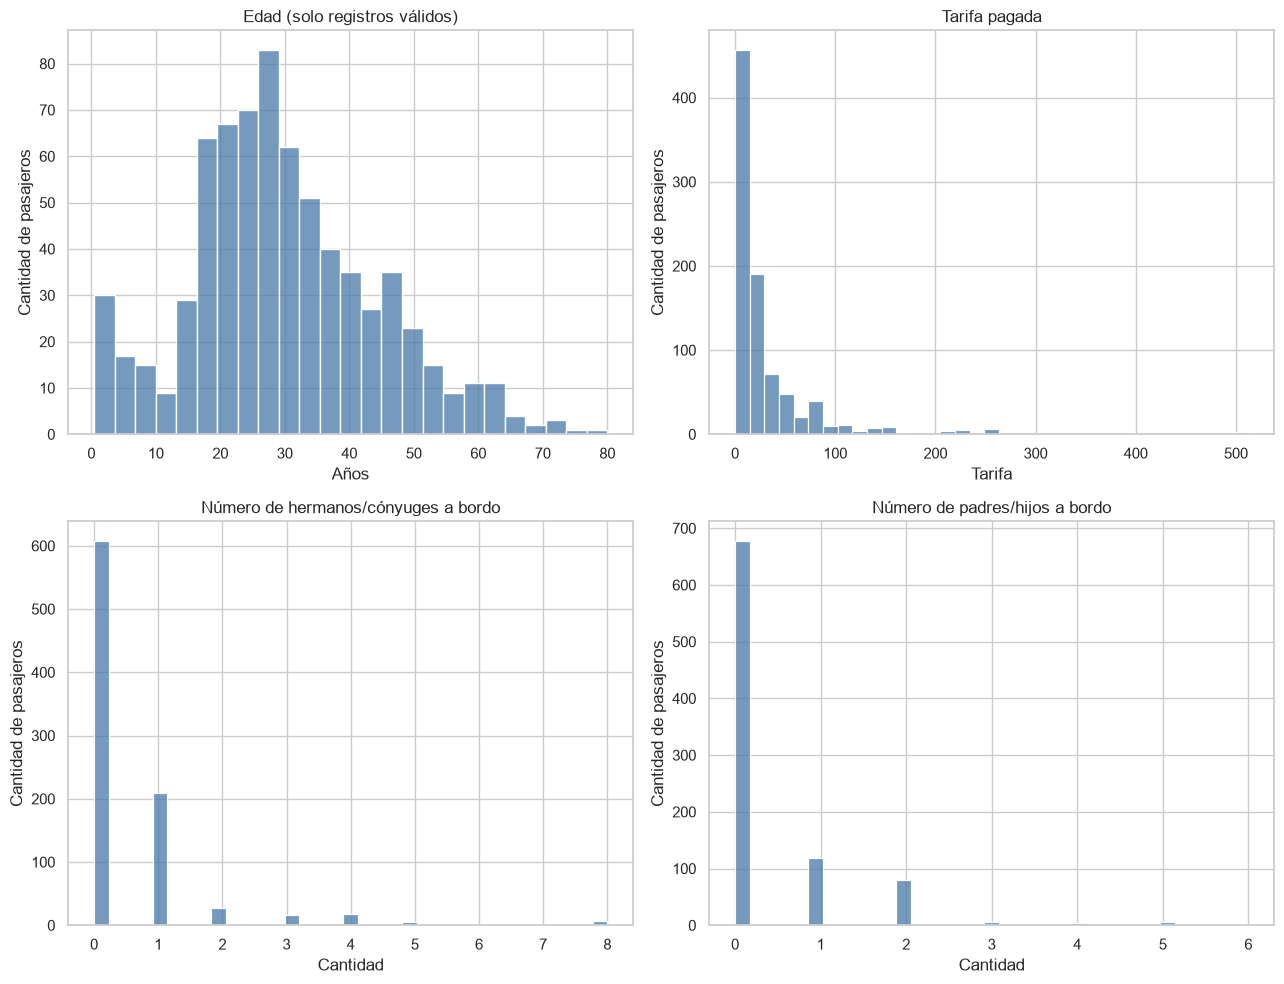

In [7]:
fig,axes=plt.subplots(2,2,figsize=(13,10))
sns.histplot(data=titanic,x='age',bins=25,ax=axes[0,0],color='#4779a8');axes[0,0].set(title='Edad (solo registros válidos)',xlabel='Años',ylabel='Cantidad de pasajeros')
sns.histplot(data=titanic,x='fare',bins=35,ax=axes[0,1],color='#4779a8');axes[0,1].set(title='Tarifa pagada',xlabel='Tarifa',ylabel='Cantidad de pasajeros')
sns.histplot(data=titanic,x='sibsp',bins=35,ax=axes[1,0],color='#4779a8');axes[1,0].set(title='Número de hermanos/cónyuges a bordo',xlabel='Cantidad',ylabel='Cantidad de pasajeros')
sns.histplot(data=titanic,x='parch',bins=35,ax=axes[1,1],color='#4779a8');axes[1,1].set(title='Número de padres/hijos a bordo',xlabel='Cantidad',ylabel='Cantidad de pasajeros')
plt.tight_layout();plt.show()


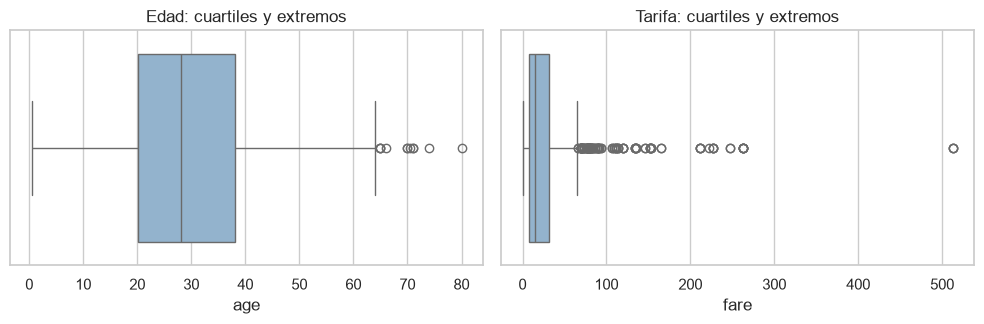

Edad: media 29.7 mediana 28.0
Tarifa: media 32.2 mediana 14.45


In [8]:
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
sns.boxplot(data=titanic,x='age',ax=axes[0],color='#89b4d7');axes[0].set(title='Edad: cuartiles y extremos')
sns.boxplot(data=titanic,x='fare',ax=axes[1],color='#89b4d7');axes[1].set(title='Tarifa: cuartiles y extremos')
plt.tight_layout();plt.show()
print('Edad: media',round(titanic.age.mean(),2),'mediana',round(titanic.age.median(),2))
print('Tarifa: media',round(titanic.fare.mean(),2),'mediana',round(titanic.fare.median(),2))

### Análisis de resultados

**Distribución de edades**

El histograma de `age` muestra una mayor concentración de pasajeros en edades adultas jóvenes, principalmente entre los 20 y 40 años, mientras que las frecuencias disminuyen hacia las edades más avanzadas.

La media de 29,70 años y la mediana de 28 años presentan valores relativamente próximos, lo que indica una diferencia moderada entre ambas medidas de tendencia central.

El diagrama de caja permite identificar algunas edades elevadas respecto del comportamiento central, aunque estos valores no constituyen necesariamente errores de registro.

**Distribución de tarifas**

La variable `fare` presenta una asimetría positiva considerable. La mayor parte de los pasajeros se concentra en tarifas relativamente bajas, mientras que un número menor registra valores considerablemente superiores.

Esta característica explica la diferencia entre la media de 32,20 y la mediana de 14,45. Asimismo, el diagrama de caja evidencia numerosos valores por encima del rango habitual de la distribución.

En consecuencia, la mediana y los cuartiles ofrecen una representación más robusta del comportamiento central de las tarifas que la media por sí sola.

**Distribución de acompañantes familiares**

Las variables `sibsp` y `parch` muestran una elevada concentración en cero, indicando que una proporción importante de pasajeros no registra acompañantes en alguna de estas categorías.

En `sibsp`, los valores alcanzan un máximo de ocho, mientras que en `parch` llegan hasta seis. Las frecuencias disminuyen considerablemente a medida que aumenta la cantidad de acompañantes registrados.

En términos generales, las distribuciones evidencian comportamientos diferentes entre las variables: mientras la edad presenta una concentración relativamente definida, las tarifas y los indicadores familiares muestran distribuciones asimétricas. Estos resultados justifican utilizar medidas descriptivas y visualizaciones adecuadas a las características particulares de cada variable.

## 6. Análisis de variables categóricas

En esta sección se analizará la distribución de frecuencias de las principales variables categóricas mediante gráficos de barras.

Se considerarán el indicador de supervivencia (`survived`), el sexo (`sex`), la clase del pasaje (`pclass`) y el puerto de embarque (`embarked`).

El objetivo es visualizar la composición de los pasajeros, identificar las categorías predominantes y reconocer posibles desequilibrios que deban tenerse en cuenta al realizar comparaciones entre grupos.

Este análisis complementa las tablas de frecuencias presentadas anteriormente, facilitando la identificación visual de patrones generales en el conjunto de datos.

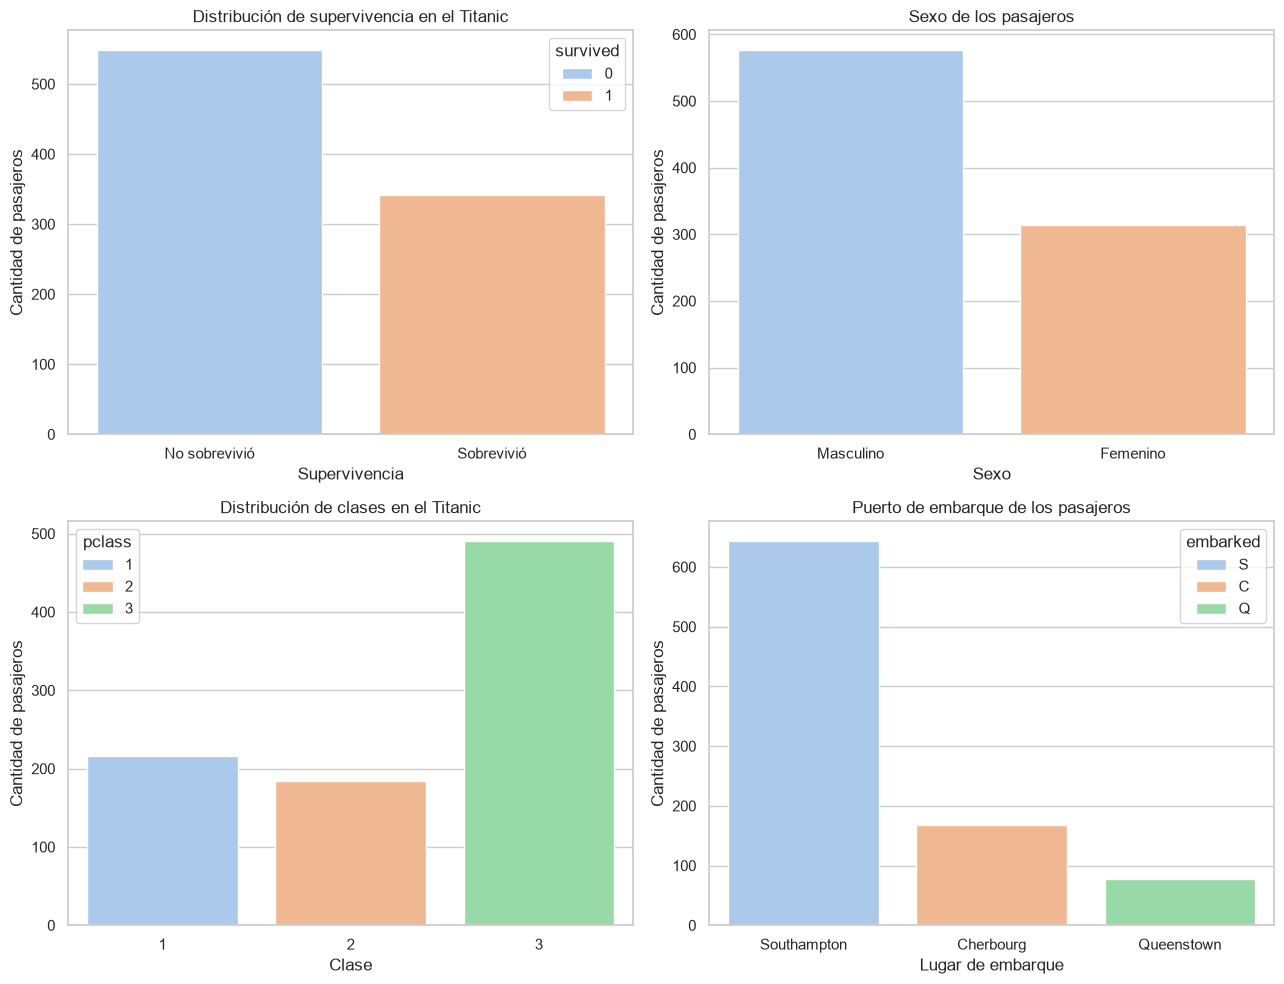

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
sns.countplot(data=titanic, x="survived", ax=axes[0,0], hue="survived", palette="pastel")
axes[0,0].set_title("Distribución de supervivencia en el Titanic")
axes[0,0].set_xlabel("Supervivencia")
axes[0,0].set_ylabel("Cantidad de pasajeros")
axes[0,0].set_xticks([0, 1])
axes[0,0].set_xticklabels(["No sobrevivió", "Sobrevivió"])

sns.countplot(data=titanic, x="sex", ax=axes[0,1], hue="sex", palette="pastel")
axes[0,1].set_title("Sexo de los pasajeros")
axes[0,1].set_xlabel("Sexo")
axes[0,1].set_ylabel("Cantidad de pasajeros")
axes[0,1].set_xticks(["male", "female"])
axes[0,1].set_xticklabels(["Masculino", "Femenino"])

sns.countplot(data=titanic, x="pclass", ax=axes[1,0], hue="pclass", palette="pastel")
axes[1,0].set_title("Distribución de clases en el Titanic")
axes[1,0].set_xlabel("Clase")
axes[1,0].set_ylabel("Cantidad de pasajeros")
#axes[1,0].set_xticks([1, 2, 3])
#axes[1,0].set_xticklabels(["Primera", "Segunda", "Tercera"])

sns.countplot(data=titanic, x="embarked", ax=axes[1,1], hue="embarked", palette="pastel")
axes[1,1].set_title("Puerto de embarque de los pasajeros")
axes[1,1].set_xlabel("Lugar de embarque")
axes[1,1].set_ylabel("Cantidad de pasajeros")
axes[1,1].set_xticks(["S", "C", "Q"])
axes[1,1].set_xticklabels(["Southampton", "Cherbourg", "Queenstown"])

plt.tight_layout()
plt.show()

### Análisis de resultados

Los gráficos de barras evidencian diferencias importantes en la distribución de los pasajeros entre las categorías analizadas.

En primer lugar, la supervivencia presenta una distribución desigual: los 549 pasajeros que no sobrevivieron superan a los 342 sobrevivientes. Esta diferencia equivale a **23,24 puntos porcentuales** entre ambas categorías.

Respecto del sexo, se observa un predominio masculino, con 577 hombres frente a 314 mujeres. Por lo tanto, los hombres representan aproximadamente dos tercios de los registros.

En cuanto a la clase, la tercera concentra más de la mitad de los pasajeros (55,11 %), mientras que primera y segunda clase presentan participaciones considerablemente menores.

Finalmente, Southampton constituye el principal puerto de embarque, concentrando el 72,28 % de los registros. Cherbourg y Queenstown presentan participaciones de 18,86 % y 8,64 %, respectivamente, mientras que dos pasajeros carecen de esta información.

Estos resultados confirman que la composición del dataset no es equilibrada entre categorías. Por ello, las comparaciones posteriores de supervivencia deberán realizarse utilizando **proporciones calculadas dentro de cada grupo**, en lugar de considerar únicamente frecuencias absolutas, para evitar interpretaciones condicionadas por las diferencias de tamaño.

## 7. Análisis de relaciones entre variables

Una vez caracterizadas las distribuciones individuales, se explorarán posibles asociaciones entre las características de los pasajeros y su supervivencia.

En primer lugar, se calcularán tasas de supervivencia según sexo, clase y condición de viaje individual, considerando el número de pasajeros de cada grupo. Posteriormente, se analizará la relación conjunta entre sexo y clase para identificar diferencias que puedan quedar ocultas en las comparaciones generales.

Adicionalmente, se examinará la relación entre edad y tarifa mediante un gráfico de dispersión, distinguiendo a los pasajeros según su condición de supervivencia.

Finalmente, se calculará una matriz de correlaciones de Pearson entre las variables numéricas `age`, `fare`, `sibsp` y `parch`, con el propósito de identificar asociaciones lineales preliminares.

Los resultados tendrán un alcance estrictamente descriptivo y no se interpretarán como evidencia de relaciones causales.

In [10]:
def resumen_grupo(columna):
    return (df.groupby(columna,dropna=False,observed=True)['survived']
              .agg(n='size',sobrevivientes='sum',tasa='mean')
              .assign(tasa_pct=lambda x:(x.tasa*100).round(2)))
for c in ['sex','pclass','viaja_solo']:
    print('Supervivencia por',c);display(resumen_grupo(c))
print('Sexo × clase (n y tasa):')
display(df.groupby(['sex','pclass'],observed=True)['survived'].agg(n='size',tasa='mean').round(3))

Supervivencia por sex


,n,sobrevivientes,tasa,tasa_pct
sex,,,,
female,314,233,0.742038,74.20
male,577,109,0.188908,18.89


Supervivencia por pclass


,n,sobrevivientes,tasa,tasa_pct
pclass,,,,
1,216,136,0.629630,62.96
2,184,87,0.472826,47.28
3,491,119,0.242363,24.24


Supervivencia por viaja_solo


,n,sobrevivientes,tasa,tasa_pct
viaja_solo,,,,
False,354,179,0.505650,50.56
True,537,163,0.303538,30.35


Sexo × clase (n y tasa):


n   tasa
sex    pclass            
female 1        94  0.968
       2        76  0.921
       3       144  0.500
male   1       122  0.369
       2       108  0.157
       3       347  0.135

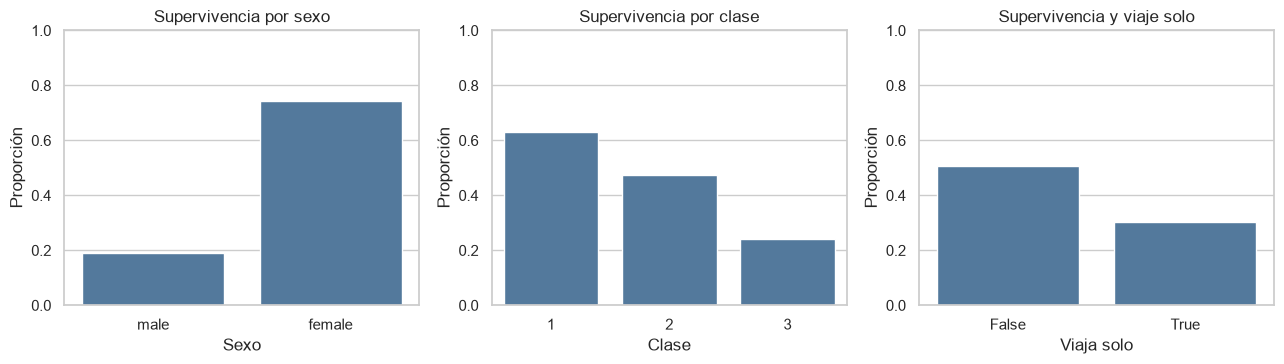

In [11]:
fig,axes=plt.subplots(1,3,figsize=(13,3.8))
sns.barplot(data=df,x='sex',y='survived',errorbar=None,ax=axes[0],color='#4779a8');axes[0].set(title='Supervivencia por sexo',ylabel='Proporción',xlabel='Sexo',ylim=(0,1))
sns.barplot(data=df,x='pclass',y='survived',errorbar=None,ax=axes[1],color='#4779a8');axes[1].set(title='Supervivencia por clase',ylabel='Proporción',xlabel='Clase',ylim=(0,1))
sns.barplot(data=df,x='viaja_solo',y='survived',errorbar=None,ax=axes[2],color='#4779a8');axes[2].set(title='Supervivencia y viaje solo',ylabel='Proporción',xlabel='Viaja solo',ylim=(0,1))
plt.tight_layout();plt.show()

### Análisis de supervivencia según características de los pasajeros

**Supervivencia por sexo**

Se observan diferencias importantes en las tasas de supervivencia según sexo. Entre las 314 mujeres registradas, 233 sobrevivieron, equivalente al **74,20 %**. En contraste, de los 577 hombres, sobrevivieron 109, correspondiente al **18,89 %**.

La diferencia alcanza aproximadamente 55,31 puntos porcentuales, evidenciando una asociación descriptiva considerable entre sexo y supervivencia.

**Supervivencia por clase**

La tasa de supervivencia presenta un comportamiento decreciente desde primera hacia tercera clase.

En primera clase sobrevivió el 62,96 % de los pasajeros, mientras que en segunda clase la proporción fue de 47,28 % y en tercera de 24,24 %.

La diferencia entre primera y tercera clase alcanza 38,72 puntos porcentuales, lo que evidencia una marcada desigualdad descriptiva entre estos grupos.

**Supervivencia según condición de viaje individual**

Entre los 354 pasajeros que registran acompañantes familiares, 179 sobrevivieron, equivalente al 50,56 %. Por su parte, entre los 537 pasajeros clasificados como viajeros solos, sobrevivieron 163, correspondiente al 30,35 %.

La diferencia de 20,21 puntos porcentuales sugiere que la supervivencia también varía según la presencia de familiares registrados a bordo.

**Análisis conjunto de sexo y clase**

La comparación simultánea de ambas variables permite identificar diferencias adicionales.

Las mujeres de primera y segunda clase presentan tasas de supervivencia de 96,8 % y 92,1 %, respectivamente, mientras que en tercera clase la proporción disminuye al 50,0 %.

Entre los hombres, las tasas son considerablemente menores: 36,9 % en primera clase, 15,7 % en segunda y 13,5 % en tercera.

Estos resultados muestran que las diferencias por sexo se mantienen dentro de cada clase, aunque su magnitud varía entre grupos.

En conjunto, la exploración evidencia asociaciones relevantes entre supervivencia, sexo, clase y composición familiar. Sin embargo, las diferencias observadas no permiten establecer relaciones causales, ya que pueden intervenir factores adicionales que no han sido controlados en esta etapa.

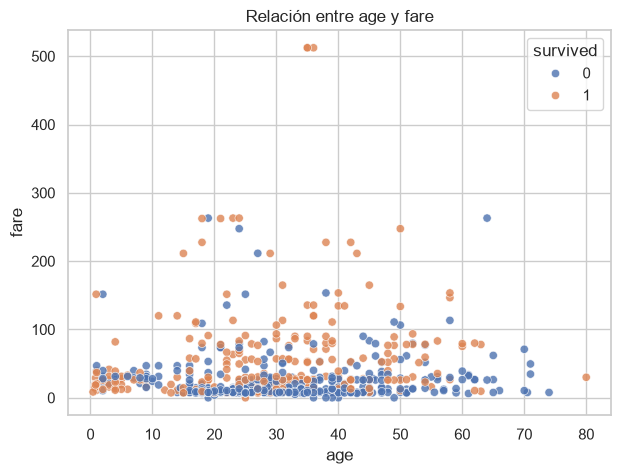

In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=titanic, x="age", y="fare", hue="survived", alpha=0.8)
plt.title("Relación entre age y fare")
plt.show()

### Análisis de dispersión entre edad y tarifa

El gráfico de dispersión permite observar la relación conjunta entre la edad de los pasajeros y la tarifa registrada, diferenciando los casos según supervivencia.

Se aprecia una concentración importante de observaciones en tarifas bajas, distribuida a lo largo de diferentes edades. Por otra parte, las tarifas elevadas corresponden a un número reducido de pasajeros y no muestran una concentración exclusiva en un intervalo etario específico.

La diferenciación por supervivencia permite reconocer que ambos resultados se presentan en distintas combinaciones de edad y tarifa. Sin embargo, la visualización no permite establecer una separación clara entre sobrevivientes y no sobrevivientes a partir de estas dos variables.

En consecuencia, no se identifica visualmente una relación lineal marcada entre edad y tarifa. Esta apreciación será complementada mediante el cálculo de correlaciones, considerando que el gráfico excluye automáticamente las observaciones sin edad registrada.

In [13]:
titanic[["age", "fare", "sibsp", "parch"]].corr()



,age,fare,sibsp,parch
age,1.000000,0.096067,-0.308247,-0.189119
fare,0.096067,1.000000,0.159651,0.216225
sibsp,-0.308247,0.159651,1.000000,0.414838
parch,-0.189119,0.216225,0.414838,1.000000


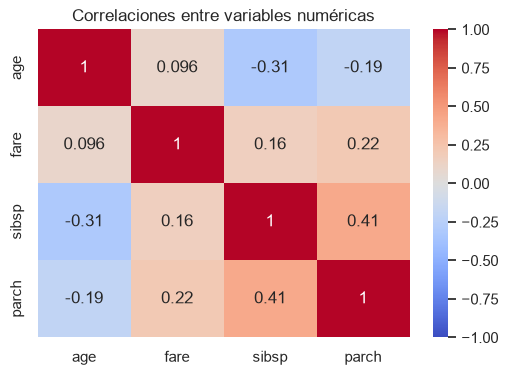

Cantidad de pares válidos por correlación:


,age,fare,sibsp,parch
age,714,714,714,714
fare,714,891,891,891
sibsp,714,891,891,891
parch,714,891,891,891


In [14]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    titanic[["age", "fare", "sibsp", "parch"]].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlaciones entre variables numéricas")
plt.show()


variables = ["age", "fare", "sibsp", "parch"]
print("Cantidad de pares válidos por correlación:")
n_pares = pd.DataFrame(
    {
        col: [
            titanic[[col, otra]].dropna().shape[0]
            for otra in variables
        ]
        for col in variables
    },
    index=variables
)

display(n_pares)


### Análisis de correlaciones entre variables numéricas

La matriz de correlaciones de Pearson permite cuantificar la dirección e intensidad de las asociaciones lineales entre las variables numéricas seleccionadas.

La asociación positiva de mayor magnitud corresponde a `sibsp` y `parch`, con un coeficiente de **0,415**, lo que indica una relación lineal positiva moderada entre ambas variables familiares.

Por otra parte, `age` y `sibsp` presentan una correlación negativa de **-0,308**, mientras que la relación entre `age` y `parch` alcanza **-0,189**. Estos resultados indican que los pasajeros de menor edad tienden, en términos generales, a registrar una mayor cantidad de acompañantes en estas categorías, aunque las asociaciones no son suficientemente intensas para describir una relación determinista.

Respecto de la tarifa, se observan correlaciones positivas débiles con `sibsp` (0,160) y `parch` (0,216).

Finalmente, la correlación entre edad y tarifa es de apenas **0,096**, lo que confirma la ausencia de una asociación lineal relevante entre ambas variables en los registros disponibles.

En conjunto, los resultados sugieren que las asociaciones lineales más destacadas se presentan entre las variables familiares, mientras que las relaciones con la tarifa son débiles. Cabe señalar que estas correlaciones no implican causalidad y que su cálculo considera únicamente las observaciones válidas para cada par de variables.

**Consideraciones sobre la cobertura de los datos**

Las correlaciones se calcularon mediante observaciones completas por pares de variables. Por ello, las asociaciones que involucran `age` utilizan 714 registros, mientras que las correlaciones entre `fare`, `sibsp` y `parch` consideran los 891 pasajeros.

Esta diferencia en la cantidad de observaciones debe tenerse presente al comparar los coeficientes, especialmente porque no se ha establecido que la ausencia de información sobre la edad ocurra de manera aleatoria.

## 8. Comparaciones descriptivas entre grupos

En esta sección se profundizará en la exploración mediante la comparación de las distribuciones de edad y tarifa entre distintos grupos de pasajeros.

Se calcularán los promedios de ambas variables según supervivencia, sexo, clase y puerto de embarque. Posteriormente, se utilizarán diagramas de caja para observar diferencias en las distribuciones y detectar posibles valores extremos.

El propósito es identificar patrones descriptivos que complementen los resultados anteriores, considerando que las diferencias entre promedios pueden estar influenciadas por la dispersión de los datos, la composición de los grupos y la presencia de observaciones atípicas.

In [15]:
print("Media por supervivencia:")
display(titanic.groupby("survived", observed=False)[["age", "fare"]].mean())

print("Media por sexo:")
display(titanic.groupby("sex", observed=False)[["age", "fare"]].mean())

print("Media por clase:")
display(titanic.groupby("pclass", observed=False)[["age", "fare"]].mean())

print("Media por embarque:")
display(titanic.groupby("embarked", observed=False)[["age", "fare"]].mean())

Media por supervivencia:


,age,fare
survived,,
0,30.626179,22.117887
1,28.343690,48.395408


Media por sexo:


,age,fare
sex,,
female,27.915709,44.479818
male,30.726645,25.523893


Media por clase:


,age,fare
pclass,,
1,38.233441,84.154687
2,29.877630,20.662183
3,25.140620,13.675550


Media por embarque:


,age,fare
embarked,,
C,30.814769,59.954144
Q,28.089286,13.276030
S,29.445397,27.079812


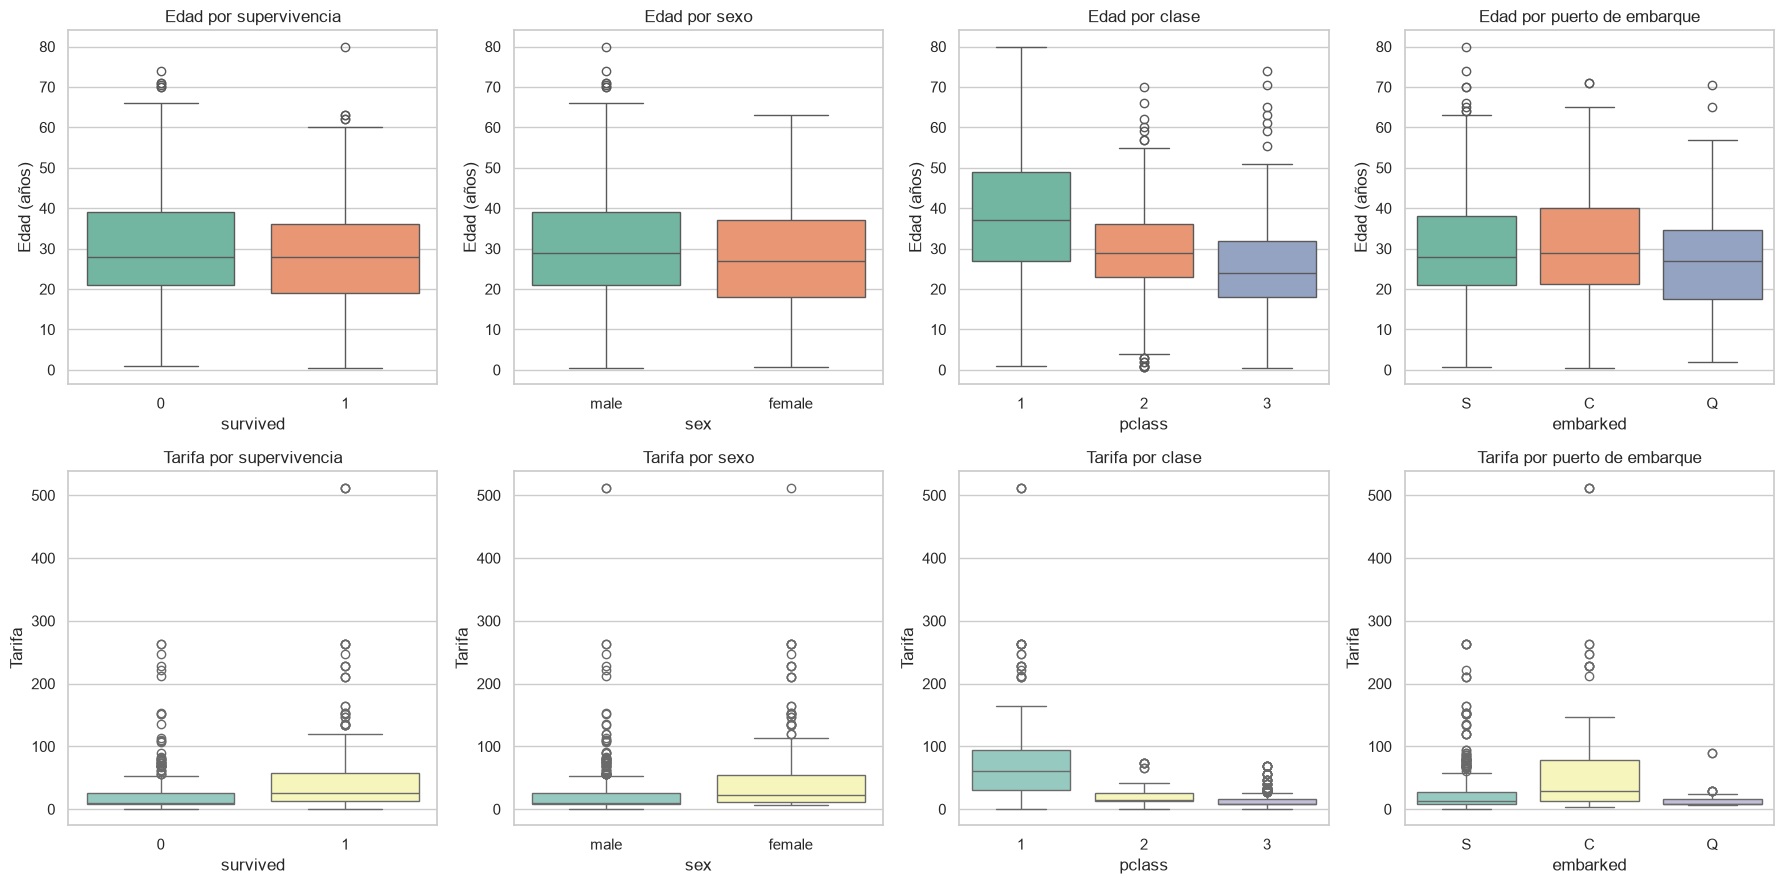

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

grupos = [
    ("survived", "supervivencia"),
    ("sex", "sexo"),
    ("pclass", "clase"),
    ("embarked", "puerto de embarque")
]

for j, (variable, nombre) in enumerate(grupos):

    sns.boxplot(data=titanic, x=variable, y="age", hue=variable, legend=False, palette="Set2",
        ax=axes[0, j]
    )

    axes[0, j].set_title(f"Edad por {nombre}")
    axes[0, j].set_xlabel(variable)
    axes[0, j].set_ylabel("Edad (años)")

    sns.boxplot(data=titanic, x=variable, y="fare", hue=variable, legend=False, palette="Set3",
        ax=axes[1, j]
    )

    axes[1, j].set_title(f"Tarifa por {nombre}")
    axes[1, j].set_xlabel(variable)
    axes[1, j].set_ylabel("Tarifa")

plt.tight_layout()
plt.show()


### Análisis de resultados

**Comparación según supervivencia**

Los pasajeros que sobrevivieron presentan una edad promedio de **28,34 años**, inferior a los 30,63 años registrados entre quienes no sobrevivieron. La diferencia es de aproximadamente 2,28 años, por lo que ambos grupos presentan promedios relativamente próximos.

En contraste, las diferencias en la tarifa son considerablemente mayores. Los sobrevivientes registran una tarifa promedio de 48,40, mientras que entre los no sobrevivientes alcanza 22,12.

Esta diferencia resulta consistente con las variaciones de supervivencia observadas entre clases, aunque no permite atribuir a la tarifa un efecto independiente sobre la supervivencia.

**Comparación según sexo**

Las mujeres presentan una edad promedio de 27,92 años, frente a 30,73 años entre los hombres.

Asimismo, la tarifa promedio de las mujeres alcanza 44,48, superior a los 25,52 registrados entre los hombres. Estas diferencias pueden estar relacionadas con la composición de los pasajeros según clase y otras características.

**Comparación según clase**

La primera clase presenta una edad promedio de 38,23 años y una tarifa promedio de 84,15. En segunda clase, estos valores disminuyen a 29,88 años y 20,66, respectivamente, mientras que en tercera clase alcanzan 25,14 años y 13,68.

Los resultados evidencian diferencias tanto etarias como económicas entre las clases, especialmente en la tarifa, cuya media en primera clase supera ampliamente a las restantes.

**Comparación según puerto de embarque**

Cherbourg presenta la tarifa promedio más elevada, con 59,95, seguido de Southampton con 27,08 y Queenstown con 13,28.

Las diferencias de edad promedio son menores: 30,81 años en Cherbourg, 29,45 en Southampton y 28,09 en Queenstown.

Estas variaciones sugieren diferencias en la composición de los pasajeros según puerto, aunque no permiten determinar sus causas.

**Interpretación de los diagramas de caja**

Los diagramas de caja permiten complementar las comparaciones de promedios, incorporando información sobre la mediana, la dispersión y la presencia de valores potencialmente atípicos.

En el caso de la edad, se observan diferencias en la distribución entre clases, con una tendencia hacia edades mayores entre los pasajeros de primera clase. Las diferencias según supervivencia y sexo son menos pronunciadas, y existe un considerable solapamiento entre las distribuciones.

Por su parte, las tarifas presentan diferencias más marcadas entre grupos, especialmente según la clase del pasaje. La primera clase muestra valores centrales superiores y una mayor dispersión, mientras que la tercera concentra tarifas considerablemente menores.

Asimismo, se identifican tarifas elevadas que se alejan del comportamiento central, lo que confirma la asimetría positiva detectada en el análisis univariante.

Estas observaciones respaldan la conveniencia de interpretar las diferencias entre grupos utilizando tanto medidas de tendencia central como indicadores de dispersión, evitando atribuir las variaciones exclusivamente a una característica individual de los pasajeros.

## 9. Detección de valores potencialmente atípicos

Con el propósito de complementar el diagnóstico de calidad, se identificarán valores potencialmente atípicos en las variables `age` y `fare` mediante el criterio del rango intercuartílico (IQR).

Este procedimiento considera como posibles valores atípicos aquellas observaciones que se encuentran por debajo de Q1 − 1,5 × IQR o por encima de Q3 + 1,5 × IQR.

Se calcularán los cuartiles, el rango intercuartílico, los límites de referencia y la cantidad de observaciones que exceden dichos límites.

Es importante señalar que la clasificación estadística de un valor como atípico no implica necesariamente que corresponda a un error. Por ello, en esta etapa los registros identificados serán conservados y documentados para su eventual revisión posterior.

In [17]:
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr
    mask = (serie < li) | (serie > ls)
    return {
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_inferior": li,
        "limite_superior": ls,
        "n_outliers": int(mask.sum()),
        "outliers": serie[mask]
    }

out_age = detectar_outliers_iqr(titanic["age"])
out_fare = detectar_outliers_iqr(titanic["fare"])

print("Resumen outliers age:")
for k, v in out_age.items():
    if k != "outliers":
        print(f"{k}: {v}")

print("\nValores outlier de age:")
print(out_age["outliers"].sort_values())

print("\n" + "="*50 + "\n")

print("Resumen outliers fare:")
for k, v in out_fare.items():
    if k != "outliers":
        print(f"{k}: {v}")

print("\nValores outlier de fare:")
print(out_fare["outliers"].sort_values())

Resumen outliers age:
q1: 20.125
q3: 38.0
iqr: 17.875
limite_inferior: -6.6875
limite_superior: 64.8125
n_outliers: 11

Valores outlier de age:
54     65.0
280    65.0
456    65.0
33     66.0
745    70.0
672    70.0
116    70.5
96     71.0
493    71.0
851    74.0
630    80.0
Name: age, dtype: float64


Resumen outliers fare:
q1: 7.9104
q3: 31.0
iqr: 23.0896
limite_inferior: -26.724
limite_superior: 65.6344
n_outliers: 116

Valores outlier de fare:
151     66.6000
336     66.6000
369     69.3000
641     69.3000
201     69.5500
         ...   
341    263.0000
438    263.0000
258    512.3292
679    512.3292
737    512.3292
Name: fare, Length: 116, dtype: float64


### Análisis de resultados

**Valores atípicos en la edad**

Para `age`, el primer cuartil corresponde a 20,125 años y el tercero a 38 años, obteniéndose un rango intercuartílico de 17,875.

A partir de estos valores, el límite inferior calculado es de -6,6875 años y el superior de 64,8125 años.

Se identificaron **11 observaciones potencialmente atípicas**, correspondientes a edades entre 65 y 80 años. Estas representan aproximadamente el 1,54 % de los 714 registros con edad conocida.

Dado que se trata de edades posibles en el contexto del dataset, no existen antecedentes suficientes para considerarlas errores de registro.

**Valores atípicos en la tarifa**

Para `fare`, el primer cuartil es 7,9104 y el tercero 31, obteniéndose un rango intercuartílico de 23,0896.

Los límites calculados corresponden a -26,724 y 65,6344, respectivamente.

Bajo este criterio, se identificaron **116 observaciones potencialmente atípicas**, equivalentes al 13,02 % de los registros.

Los valores identificados se ubican por encima del límite superior y alcanzan una tarifa máxima de 512,3292.

Esta proporción relativamente elevada es consistente con la marcada asimetría positiva observada anteriormente en la distribución de tarifas.

**Conclusión del diagnóstico**

Los resultados muestran que la presencia de valores extremos es considerablemente más frecuente en la tarifa que en la edad.

No obstante, el criterio IQR identifica observaciones alejadas del comportamiento central, pero no permite determinar por sí mismo si son incorrectas.

Por esta razón, se considera metodológicamente adecuado conservar los registros identificados y documentar su presencia, evitando introducir modificaciones que puedan alterar la distribución original sin una justificación adicional.

## 10. Síntesis de hallazgos exploratorios

Una vez completadas las etapas de inspección, descripción, transformación y comparación, se presentará una síntesis de los principales resultados obtenidos.

Esta síntesis permitirá relacionar los hallazgos con las preguntas exploratorias iniciales, destacando la calidad y cobertura del dataset, la supervivencia general, las diferencias observadas entre grupos y las características de las distribuciones numéricas.

El propósito es consolidar los resultados más relevantes de esta primera implementación y establecer una base documentada para la continuidad del proyecto.

In [18]:
total=len(df)
tasa=df.survived.mean()
n_age=df.age.isna().sum();n_deck=df.deck.isna().sum() if 'deck' in df else None
sexo=resumen_grupo('sex');clase=resumen_grupo('pclass')
print(f'P1 | {total} registros; edad faltante: {n_age} ({n_age/total:.1%}); cubierta faltante: {n_deck} ({n_deck/total:.1%})' if n_deck is not None else f'P1 | {total} registros; edad faltante: {n_age}')
print(f'P2 | Supervivencia global: {tasa:.1%} ({int(df.survived.sum())}/{total}).')
print('P3 | Tasas por sexo:',{str(k):round(v*100,1) for k,v in sexo.tasa.items()})
print('P3 | Tasas por clase:',{str(k):round(v*100,1) for k,v in clase.tasa.items()})
print(f'P4 | Edad válida: {df.age.notna().sum()}/{total}; mediana edad: {df.age.median():.1f}; mediana tarifa: {df.fare.median():.2f}.')

columnas_derivadas = df.columns.difference(titanic.columns)
print(f"Transformaciones | {len(columnas_derivadas)} "f"columnas derivadas: {list(columnas_derivadas)}; "f"filas conservadas: {len(df) == len(titanic)}")

P1 | 891 registros; edad faltante: 177 (19.9%); cubierta faltante: 688 (77.2%)
P2 | Supervivencia global: 38.4% (342/891).
P3 | Tasas por sexo: {'female': 74.2, 'male': 18.9}
P3 | Tasas por clase: {'1': 63.0, '2': 47.3, '3': 24.2}
P4 | Edad válida: 714/891; mediana edad: 28.0; mediana tarifa: 14.45.
Transformaciones | 2 columnas derivadas: ['familia_a_bordo', 'viaja_solo']; filas conservadas: True


### Registro consolidado de decisiones exploratorias

Con el propósito de garantizar la trazabilidad del análisis, se presenta un resumen de las principales decisiones metodológicas adoptadas durante esta primera fase, sus fundamentos y los resultados asociados.

| Decisión | Justificación | Resultado |
|---|---|---|
| Conservar los registros originales | No existe un identificador único que permita confirmar duplicaciones de pasajeros | Se mantienen 891 registros |
| No imputar valores faltantes | No se dispone de evidencia suficiente sobre el mecanismo de ausencia | Se documentan 177 edades y 688 cubiertas faltantes |
| Construir variables familiares | Facilitar la interpretación de la composición familiar | Se incorporan dos variables derivadas |
| Comparar tasas dentro de cada grupo | Evitar interpretaciones distorsionadas por tamaños desiguales | Se identifican diferencias de supervivencia según sexo, clase y acompañamiento familiar |
| Utilizar mediana y cuartiles | Complementar las medias ante distribuciones asimétricas | Se identifica una marcada asimetría positiva en la tarifa |
| Conservar valores potencialmente atípicos | El criterio IQR no demuestra que sean errores | Se mantienen 11 edades y 116 tarifas identificadas como atípicas |
| Limitar el alcance a resultados descriptivos | La exploración no controla factores de confusión ni establece causalidad | Se documentan asociaciones preliminares para profundizar posteriormente |

Este registro permite vincular las acciones realizadas con sus fundamentos y resultados, facilitando la revisión del proceso y su continuidad en las siguientes fases del proyecto.

### Síntesis e interpretación de los principales hallazgos

El análisis exploratorio permitió caracterizar un conjunto de 891 pasajeros y 15 variables originales, identificando patrones relevantes de supervivencia y algunas restricciones asociadas a la calidad de la información.

**Calidad y cobertura de los datos**

Se identificaron valores faltantes principalmente en `deck` (77,22 %) y `age` (19,87 %), además de 107 registros completamente duplicados. Estos resultados evidencian la necesidad de considerar las restricciones de cobertura y de evitar la eliminación automática de registros sin una evaluación adicional.

**Supervivencia general**

La tasa global de supervivencia alcanza el 38,38 %, correspondiente a 342 pasajeros. Este resultado constituye una referencia descriptiva inicial, aunque oculta diferencias importantes entre grupos.

**Diferencias según características de los pasajeros**

Las mayores variaciones descriptivas de supervivencia se observan según sexo y clase. Las mujeres presentan una tasa de 74,20 %, frente a 18,89 % entre los hombres. Asimismo, la supervivencia disminuye desde 62,96 % en primera clase hasta 24,24 % en tercera.

También se observan diferencias según la presencia de familiares registrados a bordo, con una supervivencia de 50,56 % entre quienes viajan acompañados y 30,35 % entre quienes viajan solos.

**Distribuciones y relaciones numéricas**

La edad presenta una media de 29,70 años y una mediana de 28, mientras que la tarifa muestra una marcada asimetría positiva, con una media de 32,20 y una mediana de 14,45.

La exploración de correlaciones evidencia asociaciones principalmente entre las variables familiares, mientras que la relación lineal entre edad y tarifa es débil.

**Transformaciones y trazabilidad**

Se construyeron dos variables derivadas, `familia_a_bordo` y `viaja_solo`, a partir de las variables originales `sibsp` y `parch`. La transformación se realizó sobre una copia del conjunto de datos, aumentando de 15 a 17 columnas y conservando los 891 registros originales.

La variable `viaja_solo` presentó una coincidencia del 100 % con el indicador original `alone` (891 de 891 registros), lo que constituye una comprobación de consistencia interna de la transformación. Esta validación no implica independencia entre ambas variables, dado que representan el mismo concepto.

**Supuestos y limitaciones**

Los resultados corresponden exclusivamente al conjunto de datos analizado y deben interpretarse con un alcance descriptivo. La ausencia de información en determinadas variables, la falta de un identificador único y la posible influencia de factores no observados impiden formular conclusiones causales.

Asimismo, las comparaciones de edad se basan únicamente en los registros disponibles, sin asumir que los valores faltantes se distribuyen aleatoriamente.

**Cierre del avance**

En términos generales, esta primera fase permitió establecer una base técnica reproducible para el análisis del Titanic, integrando diagnóstico de calidad, estadísticas descriptivas, visualizaciones, transformaciones y comparaciones entre grupos.

Los hallazgos permiten identificar aspectos relevantes para profundizar en etapas posteriores, particularmente la relación conjunta entre sexo, clase, edad, composición familiar y supervivencia.

La continuidad del proyecto deberá considerar una evaluación más detallada de los valores faltantes, el tratamiento de observaciones extremas y la incorporación de herramientas analíticas que permitan examinar las asociaciones identificadas con mayor profundidad.